# Reweighing on Adult, German Credit and COMPAS

**Course:** Data Wrangling (INFOMDW), Utrecht University. Assignment 4, Task 2.

**Algorithm:** Reweighing, a pre-processing bias-mitigation method from
Kamiran & Calders (2012), *Data preprocessing techniques for classification
without discrimination*, Knowledge and Information Systems 33(1), 1-33 (Section 5.2, Algorithm 3).

The notebook follows the six steps of the assignment:

1. Load three datasets (Adult, German Credit, COMPAS).
2. Compute DP_Diff, DIR and consistency from the original labels.
3. Split each dataset into train and test sets with stratification.
4. Apply Reweighing to the training set and train a classifier with the weights.
5. Report DP_Diff, DIR, consistency and predictive performance on the held-out test set.
6. Compare the fairness measures before and after mitigation.

Run all cells from top to bottom (`Kernel > Restart & Run All`). The run takes about one minute.

## 0. Setup and parameters

In [1]:
import platform
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

DATA = Path("data")
RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)

SEED = 42            # seed of the main train/test split
TEST_SIZE = 0.30     # share of rows held out for testing
K_NEIGHBOURS = 5     # k of the consistency measure
N_REPEATS = 10       # further splits (seeds 0..9) for the robustness check

MODELS = {
    "Logistic regression": lambda: LogisticRegression(C=1.0, max_iter=5000, solver="lbfgs"),
    "Decision tree": lambda: DecisionTreeClassifier(min_samples_leaf=20, random_state=0),
}

pd.set_option("display.float_format", "{:.3f}".format)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
print("python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__, "| matplotlib", matplotlib.__version__)

python 3.13.18 | numpy 2.5.3 | pandas 3.0.5 | scikit-learn 1.9.1 | matplotlib 3.11.2


## 1. Datasets

Each loader returns a table with the raw features, a column `s`
(1 = privileged group G', 0 = unprivileged group G) and a column `y`
(1 = favourable outcome).

| Dataset | File | Favourable outcome (y = 1) | Sensitive attribute | Privileged (s = 1) | Unprivileged (s = 0) |
|---|---|---|---|---|---|
| Adult | `adult.data` + `adult.test` | income > 50K | sex | Male | Female |
| German Credit | `german.data` | good credit risk | age | older than 25 | 25 or younger |
| COMPAS | `compas-scores-two-years.csv` | no re-offence within two years | race | Caucasian | African-American |

Adult uses all 48,842 rows, the same sample as the paper. Missing values form their own category.

In [2]:
ADULT_COLUMNS = ["age", "workclass", "fnlwgt", "education", "education-num", "marital-status",
                 "occupation", "relationship", "race", "sex", "capital-gain", "capital-loss",
                 "hours-per-week", "native-country", "income"]


def load_adult():
    """UCI Adult (Census Income): adult.data + adult.test, 48,842 rows."""
    parts = [pd.read_csv(DATA / "adult.data", names=ADULT_COLUMNS, skipinitialspace=True),
             pd.read_csv(DATA / "adult.test", names=ADULT_COLUMNS, skipinitialspace=True, skiprows=1)]
    df = pd.concat(parts, ignore_index=True)        # "?" (missing) stays as a category of its own
    df["y"] = df["income"].str.startswith(">50K").astype(int)
    df["s"] = (df["sex"] == "Male").astype(int)
    # fnlwgt is a census sampling weight (the paper drops it too); education duplicates education-num
    return df.drop(columns=["income", "sex", "fnlwgt", "education"])


GERMAN_COLUMNS = ["status", "duration", "credit_history", "purpose", "credit_amount", "savings",
                  "employment", "installment_rate", "personal_status_sex", "other_debtors",
                  "residence_since", "property", "age", "other_installment_plans", "housing",
                  "existing_credits", "job", "people_liable", "telephone", "foreign_worker", "credit"]


def load_german():
    """UCI Statlog German Credit: german.data, 1,000 rows (label 1 = good, 2 = bad)."""
    df = pd.read_csv(DATA / "german.data", sep=r"\s+", names=GERMAN_COLUMNS)
    df["y"] = (df["credit"] == 1).astype(int)
    df["s"] = (df["age"] > 25).astype(int)
    # age enters the analysis only through the binary sensitive attribute
    return df.drop(columns=["credit", "age"])


def load_compas():
    """ProPublica COMPAS two-year file, ProPublica's row filters, two largest race groups."""
    df = pd.read_csv(DATA / "compas-scores-two-years.csv")
    df = df[(df["days_b_screening_arrest"] <= 30) & (df["days_b_screening_arrest"] >= -30)
            & (df["is_recid"] != -1) & (df["c_charge_degree"] != "O") & (df["score_text"] != "N/A")]
    df = df[df["race"].isin(["African-American", "Caucasian"])].reset_index(drop=True)
    out = df[["age", "sex", "priors_count", "juv_fel_count", "juv_misd_count", "juv_other_count",
              "c_charge_degree"]].copy()
    out["y"] = (df["two_year_recid"] == 0).astype(int)
    out["s"] = (df["race"] == "Caucasian").astype(int)
    return out


def encode(df):
    """One-hot encode the categorical features. Returns X (without s), s and y as arrays."""
    X = pd.get_dummies(df.drop(columns=["s", "y"])).astype(float)
    return X.to_numpy(), df["s"].to_numpy(), df["y"].to_numpy()


datasets = {"Adult": load_adult(), "German": load_german(), "COMPAS": load_compas()}
encoded = {name: encode(df) for name, df in datasets.items()}

overview = pd.DataFrame.from_dict({
    name: {"rows": len(y), "encoded features": X.shape[1],
           "privileged rows": int(s.sum()), "unprivileged rows": int((1 - s).sum()),
           "favourable share": float(y.mean())}
    for name, (X, s, y) in encoded.items()}, orient="index")
overview.to_csv(RESULTS / "table0_datasets.csv")
overview

,rows,encoded features,privileged rows,unprivileged rows,favourable share
Adult,48842,89,32650,16192,0.239
German,1000,60,810,190,0.700
COMPAS,5278,9,2103,3175,0.530


## 2. Fairness measures on the original labels

The definitions follow the course slides, with G' the privileged and G the unprivileged group.

* **DP_Diff** = P(Y = 1 | G') - P(Y = 1 | G). Optimal value 0. This is the "discrimination" of the paper.
* **DIR** = P(Y = 1 | G) / P(Y = 1 | G'). Optimal value 1, fair by the 80 % rule between 0.8 and 1.25.
* **Consistency** = 1 - mean over all rows of | y_i - mean of y over kNN(x_i) |. Optimal value 1.

Consistency uses k = 5 nearest neighbours in Euclidean distance on the standardised
non-sensitive features. As in AIF360, the neighbourhood of a row includes the row itself.

These values come from the labels of the full datasets, before any split, mitigation or training.

In [3]:
def dp_diff(y, s):
    return y[s == 1].mean() - y[s == 0].mean()


def di_ratio(y, s):
    return y[s == 0].mean() / y[s == 1].mean()


def nearest_neighbours(X, k=K_NEIGHBOURS):
    return NearestNeighbors(n_neighbors=k).fit(X).kneighbors(X, return_distance=False)


def consistency(y, neighbours):
    return 1 - np.abs(y - y[neighbours].mean(axis=1)).mean()


def fairness_report(y, s, neighbours):
    return {"P(Y=1|G')": y[s == 1].mean(), "P(Y=1|G)": y[s == 0].mean(),
            "DP_Diff": dp_diff(y, s), "DIR": di_ratio(y, s), "Consistency": consistency(y, neighbours)}


original = pd.DataFrame({
    name: fairness_report(y, s, nearest_neighbours(StandardScaler().fit_transform(X)))
    for name, (X, s, y) in encoded.items()}).T
original.to_csv(RESULTS / "table1_original_labels.csv")
original

,P(Y=1|G'),P(Y=1|G),DP_Diff,DIR,Consistency
Adult,0.304,0.109,0.195,0.360,0.835
German,0.728,0.579,0.149,0.795,0.737
COMPAS,0.609,0.477,0.132,0.783,0.651


The Adult value of DP_Diff (0.1945) equals the discrimination of 19.45 % that the paper
reports for the Census Income dataset, with the same group sizes (32,650 men and 16,192 women).

## 3. and 4. Stratified split, Reweighing and training

**Split.** 70 % train, 30 % test, stratified on the four combinations of `s` and `y`,
so both sets keep the group sizes and the favourable rates of the full dataset.

**Reweighing.** Each training row with sensitive value `s` and label `y` receives the weight

W(s, y) = P(S = s) * P(Y = y) / P(S = s, Y = y)

This is the frequency expected if S and Y were independent, divided by the observed frequency.
The weights come from the training set only. The test set stays untouched.

**Classifier.** The main model is a logistic regression on standardised features.
The baseline uses no weights. The mitigated model receives the Reweighing weights as `sample_weight`.
In the main setting the sensitive attribute is not a model input, which is the paper's
primary scenario (S available for learning the weights, not for prediction).

In [4]:
def reweighing_weights(s, y):
    """Kamiran & Calders (2012), Algorithm 3. Returns one weight per row and the 2x2 weight table."""
    weights = np.empty(len(y))
    table = {}
    for s_value, group in ((1, "privileged"), (0, "unprivileged")):
        for y_value, outcome in ((1, "favourable"), (0, "unfavourable")):
            cell = (s == s_value) & (y == y_value)
            expected = (s == s_value).mean() * (y == y_value).mean()
            table[f"{group}, {outcome}"] = expected / cell.mean()
            weights[cell] = table[f"{group}, {outcome}"]
    return weights, table


def run_split(X, s, y, seed, model="Logistic regression", use_s=False):
    """One stratified split. Returns the weight table and the test-set measures."""
    rows = np.arange(len(y))
    train, test = train_test_split(rows, test_size=TEST_SIZE, stratify=2 * s + y, random_state=seed)
    scaler = StandardScaler().fit(X[train])
    X_train, X_test = scaler.transform(X[train]), scaler.transform(X[test])
    if use_s:                                          # secondary scenario: S is also a model input
        Z_train, Z_test = np.column_stack([X_train, s[train]]), np.column_stack([X_test, s[test]])
    else:
        Z_train, Z_test = X_train, X_test

    weights, table = reweighing_weights(s[train], y[train])
    # property stated in the paper: the weighted training set has zero discrimination
    weighted_rate = lambda g: np.average(y[train][s[train] == g], weights=weights[s[train] == g])
    assert abs(weighted_rate(1) - weighted_rate(0)) < 1e-9

    baseline = MODELS[model]().fit(Z_train, y[train])
    mitigated = MODELS[model]().fit(Z_train, y[train], sample_weight=weights)

    neighbours = nearest_neighbours(X_test)            # non-sensitive features of the test rows
    result = {"Test labels": fairness_report(y[test], s[test], neighbours)}
    for label, predictions in (("Baseline", baseline.predict(Z_test)),
                               ("Reweighing", mitigated.predict(Z_test))):
        result[label] = {**fairness_report(predictions, s[test], neighbours),
                         "Accuracy": accuracy_score(y[test], predictions),
                         "Balanced acc.": balanced_accuracy_score(y[test], predictions)}
    return table, result


# Check against the paper: Example 3 (job-application data of Table 1) gives the weights
# 1.5 (female, +), 0.67 (female, -), 0.75 (male, +) and 2 (male, -).
example_s = np.array([1, 1, 1, 1, 1, 0, 0, 0, 0, 0])      # 1 = male (favoured), 0 = female (deprived)
example_y = np.array([1, 1, 1, 1, 0, 0, 0, 1, 0, 1])      # 1 = "+"
_, example_table = reweighing_weights(example_s, example_y)
assert np.allclose(list(example_table.values()), [0.75, 2.0, 1.5, 2 / 3])
pd.Series(example_table, name="weight, paper Example 3").round(2)

privileged, favourable       0.750
privileged, unfavourable     2.000
unprivileged, favourable     1.500
unprivileged, unfavourable   0.670
Name: weight, paper Example 3, dtype: float64

The implementation returns the weights of the paper's worked example. The next cell runs the main split.

In [5]:
SCENARIOS = {"S not an input": False, "S as input": True}
main_run = {(name, scenario): run_split(X, s, y, SEED, use_s=use_s)
            for name, (X, s, y) in encoded.items() for scenario, use_s in SCENARIOS.items()}

weight_table = pd.DataFrame({name: main_run[(name, "S not an input")][0] for name in encoded}).T
weight_table.to_csv(RESULTS / "table2_reweighing_weights.csv")
print(f"Reweighing weights W(s, y) on the training set (seed {SEED})")
weight_table

Reweighing weights W(s, y) on the training set (seed 42)


,"privileged, favourable","privileged, unfavourable","unprivileged, favourable","unprivileged, unfavourable"
Adult,0.788,1.093,2.191,0.854
German,0.961,1.105,1.209,0.712
COMPAS,0.869,1.204,1.111,0.899


Rows of the unprivileged group with a favourable label and rows of the privileged group with an
unfavourable label receive weights above 1. The other two cells receive weights below 1.
The weights depend only on `s` and `y`, so they are the same in both scenarios.

## 5. Results on the held-out test set

Main split (seed 42), logistic regression. `Baseline` is the model without mitigation,
`Reweighing` is the same model trained with the weights. Two scenarios, as in the paper:

* **S not an input**: the sensitive attribute only serves to compute the weights (the paper's primary scenario).
* **S as input**: the classifier also receives the sensitive attribute as a feature.

In [6]:
rows = []
for name in encoded:
    rows.append({"Dataset": name, "Scenario": "-", "Stage": "Test labels",
                 **main_run[(name, "S not an input")][1]["Test labels"]})
    for scenario in SCENARIOS:
        for stage in ("Baseline", "Reweighing"):
            rows.append({"Dataset": name, "Scenario": scenario, "Stage": stage,
                         **main_run[(name, scenario)][1][stage]})
test_results = pd.DataFrame(rows).set_index(["Dataset", "Scenario", "Stage"])
test_results.to_csv(RESULTS / "table3_test_results_seed42.csv")
test_results

P(Y=1|G')  P(Y=1|G)  DP_Diff   DIR  Consistency  Accuracy  Balanced acc.
Dataset Scenario       Stage                                                                                
Adult   -              Test labels      0.304     0.109    0.194 0.360        0.827       NaN            NaN
        S not an input Baseline         0.253     0.080    0.172 0.319        0.949     0.852          0.765
                       Reweighing       0.212     0.123    0.089 0.580        0.950     0.847          0.749
        S as input     Baseline         0.255     0.078    0.177 0.305        0.948     0.852          0.766
                       Reweighing       0.209     0.128    0.081 0.614        0.950     0.846          0.747
German  -              Test labels      0.728     0.579    0.149 0.795        0.724       NaN            NaN
        S not an input Baseline         0.844     0.737    0.107 0.873        0.843     0.770          0.667
                       Reweighing       0.848     0.772    0.076 0.911        0.847     0.780          0.675
        S as input     Baseline         0.852     0.702    0.150 0.824        0.854     0.770          0.667
                       Reweighing       0.844     0.807    0.037 0.957        0.843     0.777          0.669
COMPAS  -              Test labels      0.609     0.476    0.132 0.783        0.638       NaN            NaN
        S not an input Baseline         0.748     0.493    0.255 0.659        0.980     0.667          0.662
                       Reweighing       0.756     0.507    0.249 0.670        0.979     0.667          0.661
        S as input     Baseline         0.762     0.483    0.280 0.633        0.973     0.669          0.664
                       Reweighing       0.567     0.622   -0.055 1.097        0.879     0.640          0.634

### Robustness: ten further stratified splits

The same pipeline with seeds 0 to 9, for three settings:

* logistic regression, S not an input,
* logistic regression, S as input,
* a decision tree, S not an input (the paper states that preprocessing works better with unstable classifiers).

In [7]:
SETTINGS = {"LR, S not an input": ("Logistic regression", False),
            "LR, S as input": ("Logistic regression", True),
            "Tree, S not an input": ("Decision tree", False)}

records = []
for setting, (model, use_s) in SETTINGS.items():
    for name, (X, s, y) in encoded.items():
        for seed in range(N_REPEATS):
            _, result = run_split(X, s, y, seed, model=model, use_s=use_s)
            for stage in ("Baseline", "Reweighing"):
                records.append({"Setting": setting, "Dataset": name, "Stage": stage, "seed": seed,
                                **result[stage]})
repeats = pd.DataFrame(records)
repeats.to_csv(RESULTS / "repeats_all_seeds.csv", index=False)

measures = ["DP_Diff", "DIR", "Consistency", "Accuracy", "Balanced acc."]
summary = repeats.groupby(["Setting", "Dataset", "Stage"], sort=False)[measures].agg(["mean", "std"])
summary.to_csv(RESULTS / "table4_repeats_mean_std.csv")
summary

DP_Diff         DIR       Consistency       Accuracy       Balanced acc.      
                                           mean   std  mean   std        mean   std     mean   std          mean   std
Setting              Dataset Stage                                                                                    
LR, S not an input   Adult   Baseline     0.174 0.004 0.314 0.011       0.948 0.001    0.852 0.002         0.766 0.004
                             Reweighing   0.091 0.005 0.572 0.021       0.948 0.001    0.847 0.003         0.749 0.004
                     German  Baseline     0.136 0.067 0.831 0.082       0.829 0.014    0.755 0.016         0.673 0.019
                             Reweighing   0.096 0.066 0.880 0.081       0.831 0.015    0.750 0.016         0.663 0.025
                     COMPAS  Baseline     0.234 0.024 0.685 0.030       0.976 0.004    0.679 0.005         0.673 0.005
                             Reweighing   0.224 0.024 0.702 0.031       0.976 0.004    0.677 0.007         0.670 0.007
LR, S as input       Adult   Baseline     0.180 0.004 0.296 0.011       0.948 0.001    0.853 0.003         0.767 0.004
                             Reweighing   0.085 0.005 0.597 0.022       0.948 0.002    0.846 0.002         0.748 0.004
                     German  Baseline     0.219 0.092 0.733 0.108       0.829 0.017    0.754 0.016         0.671 0.022
                             Reweighing   0.067 0.073 0.917 0.090       0.830 0.016    0.751 0.015         0.666 0.023
                     COMPAS  Baseline     0.279 0.030 0.636 0.036       0.963 0.005    0.680 0.007         0.675 0.007
                             Reweighing  -0.040 0.019 1.069 0.034       0.881 0.007    0.660 0.008         0.655 0.008
Tree, S not an input Adult   Baseline     0.169 0.007 0.325 0.017       0.919 0.003    0.856 0.002         0.769 0.003
                             Reweighing   0.089 0.006 0.588 0.023       0.920 0.002    0.851 0.002         0.757 0.005
                     German  Baseline     0.095 0.073 0.877 0.096       0.779 0.026    0.709 0.014         0.626 0.018
                             Reweighing   0.097 0.043 0.874 0.058       0.777 0.039    0.715 0.021         0.632 0.029
                     COMPAS  Baseline     0.206 0.023 0.703 0.032       0.932 0.012    0.664 0.015         0.661 0.016
                             Reweighing   0.204 0.022 0.709 0.030       0.927 0.007    0.664 0.009         0.660 0.010

## 6. Before and after mitigation

The table places the stages side by side: the original labels of the full dataset (step 2),
then the baseline classifier and the classifier trained after Reweighing (test set, seed 42)
in both scenarios. The last column gives the share of the baseline DP_Diff that Reweighing removes.

In [8]:
stages = []
for name in encoded:
    stages.append({"Dataset": name, "Scenario": "-", "Stage": "Original labels",
                   **original.loc[name, ["DP_Diff", "DIR", "Consistency"]]})
    for scenario in SCENARIOS:
        result = main_run[(name, scenario)][1]
        for stage in ("Baseline", "Reweighing"):
            row = {"Dataset": name, "Scenario": scenario, "Stage": stage,
                   **{m: result[stage][m] for m in ["DP_Diff", "DIR", "Consistency", "Accuracy"]}}
            if stage == "Reweighing":
                row["DP_Diff removed"] = 1 - abs(result["Reweighing"]["DP_Diff"]) / abs(result["Baseline"]["DP_Diff"])
            stages.append(row)
comparison = pd.DataFrame(stages).set_index(["Dataset", "Scenario", "Stage"])
comparison.to_csv(RESULTS / "table5_before_after.csv")
comparison

DP_Diff   DIR  Consistency  Accuracy  DP_Diff removed
Dataset Scenario       Stage                                                                 
Adult   -              Original labels    0.195 0.360        0.835       NaN              NaN
        S not an input Baseline           0.172 0.319        0.949     0.852              NaN
                       Reweighing         0.089 0.580        0.950     0.847            0.482
        S as input     Baseline           0.177 0.305        0.948     0.852              NaN
                       Reweighing         0.081 0.614        0.950     0.846            0.545
German  -              Original labels    0.149 0.795        0.737       NaN              NaN
        S not an input Baseline           0.107 0.873        0.843     0.770              NaN
                       Reweighing         0.076 0.911        0.847     0.780            0.290
        S as input     Baseline           0.150 0.824        0.854     0.770              NaN
                       Reweighing         0.037 0.957        0.843     0.777            0.756
COMPAS  -              Original labels    0.132 0.783        0.651       NaN              NaN
        S not an input Baseline           0.255 0.659        0.980     0.667              NaN
                       Reweighing         0.249 0.670        0.979     0.667            0.022
        S as input     Baseline           0.280 0.633        0.973     0.669              NaN
                       Reweighing        -0.055 1.097        0.879     0.640            0.804

The figure shows the mean DP_Diff over the ten splits (seeds 0 to 9) before and after Reweighing,
with one standard deviation as whiskers. The text on the right gives the mean accuracy before and after.

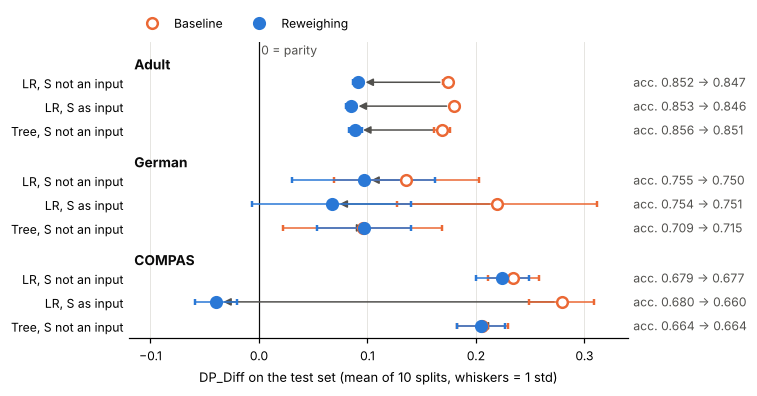

In [9]:
BASELINE_COLOUR, REWEIGHING_COLOUR, INK, MUTED = "#eb6834", "#2a78d6", "#0b0b0b", "#52514e"
mean = repeats.groupby(["Dataset", "Setting", "Stage"])[["DP_Diff", "Accuracy"]].mean()
std = repeats.groupby(["Dataset", "Setting", "Stage"])["DP_Diff"].std()

fig, ax = plt.subplots(figsize=(7.0, 3.7))
position, ticks, tick_labels = 0.0, [], []
for name in encoded:
    ax.text(-0.115, position - 0.75, name, fontsize=9, fontweight="bold", color=INK, va="center")
    for setting in SETTINGS:
        before, after = mean.loc[(name, setting, "Baseline")], mean.loc[(name, setting, "Reweighing")]
        ax.annotate("", xy=(after["DP_Diff"], position), xytext=(before["DP_Diff"], position),
                    arrowprops=dict(arrowstyle="-|>", color=MUTED, linewidth=1.0, shrinkA=5, shrinkB=5))
        for stage, colour, face in (("Baseline", BASELINE_COLOUR, "white"),
                                    ("Reweighing", REWEIGHING_COLOUR, REWEIGHING_COLOUR)):
            ax.errorbar(mean.loc[(name, setting, stage), "DP_Diff"], position,
                        xerr=std.loc[(name, setting, stage)], fmt="o", markersize=7, color=colour,
                        markerfacecolor=face, markeredgewidth=1.6, elinewidth=1.0, capsize=2, zorder=3)
        ax.text(0.345, position, f"acc. {before['Accuracy']:.3f} → {after['Accuracy']:.3f}",
                fontsize=8, color=MUTED, va="center")
        ticks.append(position)
        tick_labels.append(setting)
        position += 1
    position += 1.1
ax.axvline(0, color=INK, linewidth=0.8)
ax.text(0.002, -1.35, "0 = parity", fontsize=8, color=MUTED, va="center")
ax.set_yticks(ticks, tick_labels, fontsize=8)
ax.set_ylim(position - 1.6, -1.7)
ax.set_xlim(-0.12, 0.34)
ax.set_xlabel("DP_Diff on the test set (mean of 10 splits, whiskers = 1 std)", fontsize=8.5)
ax.tick_params(axis="x", labelsize=8)
ax.tick_params(axis="y", length=0)
ax.grid(axis="x", color="#e4e3df", linewidth=0.6)
ax.set_axisbelow(True)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
handles = [plt.Line2D([], [], marker="o", linestyle="", markersize=7, markeredgewidth=1.6,
                      color=BASELINE_COLOUR, markerfacecolor="white", label="Baseline"),
           plt.Line2D([], [], marker="o", linestyle="", markersize=7, markeredgewidth=1.6,
                      color=REWEIGHING_COLOUR, markerfacecolor=REWEIGHING_COLOUR, label="Reweighing")]
ax.legend(handles=handles, frameon=False, fontsize=8, ncol=2, loc="lower left", bbox_to_anchor=(0.0, 1.0))
fig.tight_layout()
fig.savefig(RESULTS / "figure_dp_diff_before_after.png", dpi=200, bbox_inches="tight")
fig.savefig(RESULTS / "figure_dp_diff_before_after.pdf", bbox_inches="tight")
plt.show()

## 7. Diagnostic: how well do the non-sensitive features reveal S?

Reweighing changes the joint frequencies of `s` and `y`. A classifier without `s` as input can
only react to the weights through features that are associated with `s`. The cell below measures
that association: the 5-fold cross-validated AUC of a logistic regression that predicts `s` from
the non-sensitive features (0.5 = no information, 1 = `s` fully recoverable).

In [10]:
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
proxy_model = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=5000))
proxy_auc = pd.Series({name: cross_val_score(proxy_model, X, s, cv=folds, scoring="roc_auc").mean()
                       for name, (X, s, y) in encoded.items()}, name="AUC for predicting S from X")
proxy_auc.to_csv(RESULTS / "table6_proxy_auc.csv")
proxy_auc

Adult    0.930
German   0.802
COMPAS   0.686
Name: AUC for predicting S from X, dtype: float64